# Fraud Detection for Digital Transactions

**Project Domain:** Machine Learning  
**Dataset Source:** Kaggle Fraud Detection Dataset  
**Target Variable:** `isFraud`

## Project Overview

This project aims to analyze digital financial transactions and identify potentially fraudulent activities using machine learning techniques.

The dataset contains transaction details such as transaction type, amount, account balances, and fraud labels.

## Project Workflow

1. Dataset Setup and Verification
2. Exploratory Data Analysis (EDA)
3. Data Cleaning and Preprocessing
4. Feature Engineering and Selection
5. Model Building
6. Model Evaluation
7. Results and Conclusion

# Stage 1: Project Setup and Dataset Verification

## Objective

To locate, load, and verify the dataset before performing Exploratory Data Analysis (EDA) and data preprocessing.

### Tasks
- Verify access to Google Drive.
- Locate the dataset file.
- Check the dataset's file size.
- Display sample records.
- Determine the total number of rows and columns.
- Inspect column names and data types.
- Check missing values and duplicate records.
- Analyze the distribution of fraudulent and legitimate transactions.

### Target Variable

The target variable is `isFraud`.

- `0` — Legitimate transaction
- `1` — Fraudulent transaction

In [ ]:
import os
print(os.listdir('/content/drive'))

['.shortcut-targets-by-id', 'MyDrive', '.Trash-0', '.Encrypted']


In [ ]:
print(os.listdir('/content/drive/MyDrive'))

['Colab Notebooks', 'Datasets', 'Fraud_Detection_Project_Synopsis.gdoc']


In [ ]:
folder_path = "/content/drive/MyDrive/Datasets"
print(os.listdir(folder_path))

['Telco_Customer_Churn.csv', 'pend-gdis-1960-2018-disasterlocations.csv', 'district_nwic.GeoJSON', 'historical_risk_heatmap.geojson', 'ipl.csv', 'AIML Dataset.csv']


In [ ]:
file_path = "/content/drive/MyDrive/Datasets/AIML Dataset.csv"

if os.path.exists(file_path):
    size_gb = os.path.getsize(file_path) / (1024**3)

    print("Dataset found!")
    print("File path:", file_path)
    print(f"File size: {size_gb:.2f} GB")
else:
    print("Dataset file not found. Check the file path.")

Dataset found!
File path: /content/drive/MyDrive/Datasets/AIML Dataset.csv
File size: 0.46 GB


In [ ]:
import pandas as pd

df_sample = pd.read_csv(file_path, nrows=5)

print("Column names:")
print(df_sample.columns.tolist())

print("\nFirst five records:")
display(df_sample)

Column names:
['step', 'type', 'amount', 'nameOrig', 'oldbalanceOrg', 'newbalanceOrig', 'nameDest', 'oldbalanceDest', 'newbalanceDest', 'isFraud', 'isFlaggedFraud']

First five records:


,step,type,amount,nameOrig,oldbalanceOrg,newbalanceOrig,nameDest,oldbalanceDest,newbalanceDest,isFraud,isFlaggedFraud
0,1,PAYMENT,9839.64,C1231006815,170136.0,160296.36,M1979787155,0.0,0.0,0,0
1,1,PAYMENT,1864.28,C1666544295,21249.0,19384.72,M2044282225,0.0,0.0,0,0
2,1,TRANSFER,181.00,C1305486145,181.0,0.00,C553264065,0.0,0.0,1,0
3,1,CASH_OUT,181.00,C840083671,181.0,0.00,C38997010,21182.0,0.0,1,0
4,1,PAYMENT,11668.14,C2048537720,41554.0,29885.86,M1230701703,0.0,0.0,0,0


The CSV file is relatively large, we will read it in chunks instead of loading the entire dataset into memory at once.

This helps reduce memory usage while verifying the dataset's dimensions.

In [ ]:
# Initialize counters
total_rows = 0
total_columns = 0

# Read the dataset in chunks
for chunk in pd.read_csv(file_path, chunksize=100000):
    total_rows += len(chunk)
    total_columns = len(chunk.columns)

# Display dataset dimensions
print("Total rows:", total_rows)
print("Total columns:", total_columns)
print("Dataset shape:", (total_rows, total_columns))

Total rows: 6362620
Total columns: 11
Dataset shape: (6362620, 11)


In [ ]:
# Inspect data types using a sample of 10,000 records
df_inspect = pd.read_csv(file_path, nrows=10000)

print("Column names:")
print(df_inspect.columns.tolist())

print("\nData types:")
print(df_inspect.dtypes)

print("\nSample dataset information:")
df_inspect.info()

Column names:
['step', 'type', 'amount', 'nameOrig', 'oldbalanceOrg', 'newbalanceOrig', 'nameDest', 'oldbalanceDest', 'newbalanceDest', 'isFraud', 'isFlaggedFraud']

Data types:
step                int64
type               object
amount            float64
nameOrig           object
oldbalanceOrg     float64
newbalanceOrig    float64
nameDest           object
oldbalanceDest    float64
newbalanceDest    float64
isFraud             int64
isFlaggedFraud      int64
dtype: object

Sample dataset information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 10000 entries, 0 to 9999
Data columns (total 11 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   step            10000 non-null  int64  
 1   type            10000 non-null  object 
 2   amount          10000 non-null  float64
 3   nameOrig        10000 non-null  object 
 4   oldbalanceOrg   10000 non-null  float64
 5   newbalanceOrig  10000 non-null  float64
 6   nameDest        1000

In [ ]:
# Initialize missing-value counters
missing_values = pd.Series(dtype="int64")

# Read the dataset in chunks
for chunk in pd.read_csv(file_path, chunksize=100000):

    # Count missing values in each column
    chunk_missing = chunk.isnull().sum()

    # Accumulate the counts
    if missing_values.empty:
        missing_values = chunk_missing
    else:
        missing_values += chunk_missing

# Display results
print("Missing Values in Each Column:")
display(missing_values.to_frame(name="Missing Count"))

print("\nTotal missing values:", missing_values.sum())

Missing Values in Each Column:


,Missing Count
step,0
type,0
amount,0
nameOrig,0
oldbalanceOrg,0
newbalanceOrig,0
nameDest,0
oldbalanceDest,0
newbalanceDest,0
isFraud,0



Total missing values: 0


In [ ]:
# Initialize the duplicate counter
duplicate_count = 0

# Keep track of previously encountered complete rows
seen_rows = set()

# Read the dataset in chunks
for chunk in pd.read_csv(file_path, chunksize=100000):

    # Convert each complete row into a hashable tuple
    for row in chunk.itertuples(index=False, name=None):

        if row in seen_rows:
            duplicate_count += 1
        else:
            seen_rows.add(row)

print("Total duplicate records:", duplicate_count)

Total duplicate records: 0


In [ ]:
# Initialize fraud counters
fraud_counts = {0: 0, 1: 0}

# Read the dataset in chunks
for chunk in pd.read_csv(
    file_path,
    usecols=["isFraud"],
    chunksize=100000
):

    # Count legitimate and fraudulent transactions
    counts = chunk["isFraud"].value_counts()

    for label, count in counts.items():
        fraud_counts[int(label)] += int(count)

# Convert counts to a Pandas Series
fraud_distribution = pd.Series(
    fraud_counts,
    name="Transaction Count"
)

fraud_distribution.index = [
    "Legitimate (0)",
    "Fraudulent (1)"
]

# Calculate percentages
total_transactions = fraud_distribution.sum()

fraud_percentage = (
    fraud_distribution / total_transactions * 100
)

# Display results
results = pd.DataFrame({
    "Transaction Count": fraud_distribution,
    "Percentage (%)": fraud_percentage
})

print("Fraud Distribution:")
display(results)

print("\nTotal transactions:", total_transactions)

Fraud Distribution:


,Transaction Count,Percentage (%)
Legitimate (0),6354407,99.870918
Fraudulent (1),8213,0.129082



Total transactions: 6362620


## Dataset Verification Findings

The initial verification of the dataset produced the following results:

- **Total records:** 6,362,620
- **Total columns:** 11
- **Missing values:** 0
- **Legitimate transactions:** 6,354,407 (99.8709%)
- **Fraudulent transactions:** 8,213 (0.1291%)

### Conclusion

The dataset contains no missing values in the inspected columns. However, the target variable `isFraud` is highly imbalanced because fraudulent transactions represent only a very small proportion of the dataset.

This imbalance must be considered during model development. Accuracy alone will not be sufficient to evaluate model performance because a model could achieve high accuracy while failing to identify fraudulent transactions.

# Stage 2: Exploratory Data Analysis (EDA)

## Objective

Exploratory Data Analysis helps us understand the structure, distribution, and relationships within the transaction dataset before preprocessing and model development.

In this stage, we will investigate:

1. The distribution of transaction types.
2. The distribution of transaction amounts.
3. The distribution of legitimate and fraudulent transactions.
4. Fraud rates across transaction types.
5. Differences in transaction amounts between legitimate and fraudulent transactions.

We will use Pandas, Matplotlib, and Seaborn to create meaningful visualizations and identify patterns that may help with fraud detection.

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Set the general plotting style
sns.set_theme(style="whitegrid")

print("Visualization libraries imported successfully.")

Visualization libraries imported successfully.


In [ ]:
import os

# Check system memory on Google Colab
with open("/proc/meminfo", "r") as file:
    memory_info = file.readlines()

memory_values = {}

for line in memory_info:
    if line.startswith("MemTotal:") or line.startswith("MemAvailable:"):
        key = line.split(":")[0]
        value_kb = int(line.split()[1])
        memory_values[key] = value_kb / (1024**2)

print(f"Total RAM: {memory_values['MemTotal']:.2f} GB")
print(f"Available RAM: {memory_values['MemAvailable']:.2f} GB")

Total RAM: 12.67 GB
Available RAM: 8.47 GB


## Loading Data for Exploratory Data Analysis

The dataset contains 6,362,620 transactions and 11 columns. Before analyzing the data, we will load the required columns and inspect their structure.

To manage memory efficiently, we will use a reproducible sample for initial visualizations and use the full dataset when calculating overall transaction statistics.

A fixed random seed will ensure that the sample can be reproduced.

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Dataset path
file_path = "/content/drive/MyDrive/Datasets/AIML Dataset.csv"

# Load the complete dataset
df = pd.read_csv(file_path)

# Create a reproducible sample for visualizations
df_eda = df.sample(n=200_000, random_state=42).reset_index(drop=True)

print("Dataset loaded successfully!")
print("Complete dataset shape:", df.shape)
print("EDA sample shape:", df_eda.shape)

display(df_eda.head())

Dataset loaded successfully!
Complete dataset shape: (6362620, 11)
EDA sample shape: (200000, 11)


,step,type,amount,nameOrig,oldbalanceOrg,newbalanceOrig,nameDest,oldbalanceDest,newbalanceDest,isFraud,isFlaggedFraud
0,278,CASH_IN,330218.42,C632336343,20866.00,351084.42,C834976624,452419.57,122201.15,0,0
1,15,PAYMENT,11647.08,C1264712553,30370.00,18722.92,M215391829,0.00,0.00,0,0
2,10,CASH_IN,152264.21,C1746846248,106589.00,258853.21,C1607284477,201303.01,49038.80,0,0
3,403,TRANSFER,1551760.63,C333676753,0.00,0.00,C1564353608,3198359.45,4750120.08,0,0
4,206,CASH_IN,78172.30,C813403091,2921331.58,2999503.88,C1091768874,415821.90,337649.60,0,0


## Distribution of Transaction Types

This analysis examines the frequency of each transaction type in the dataset.

A bar chart will help identify the most common transaction types and less frequent categories. Understanding transaction activity is useful for investigating whether fraud patterns differ across transaction types.

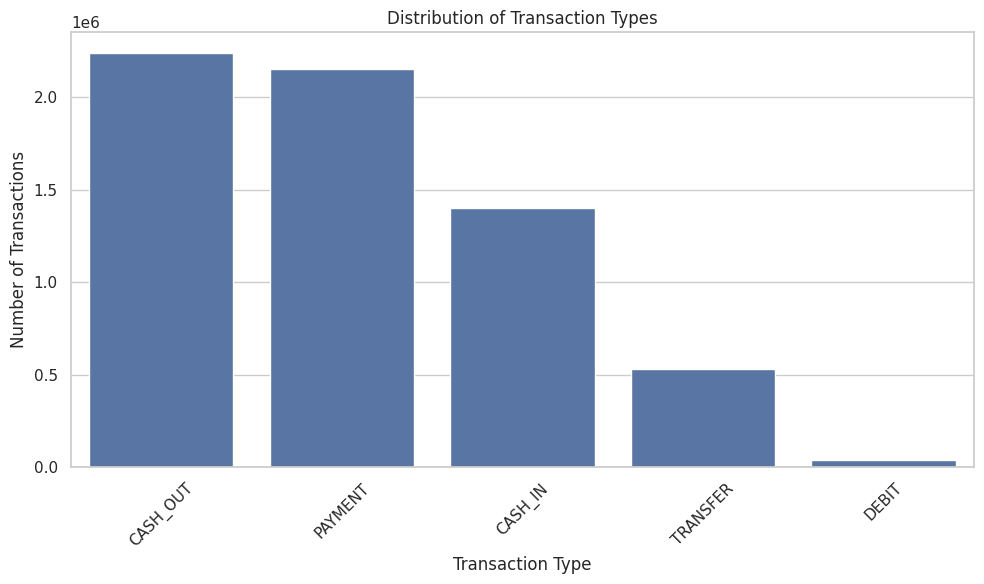

,Transaction Count
type,
CASH_OUT,2237500
PAYMENT,2151495
CASH_IN,1399284
TRANSFER,532909
DEBIT,41432


In [ ]:
# Count transactions by type in the complete dataset
transaction_counts = df["type"].value_counts()

# Create a bar chart
plt.figure(figsize=(10, 6))

sns.barplot(
    x=transaction_counts.index,
    y=transaction_counts.values
)

plt.title("Distribution of Transaction Types")
plt.xlabel("Transaction Type")
plt.ylabel("Number of Transactions")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

# Display exact counts
display(transaction_counts.to_frame(name="Transaction Count"))

##  Distribution of Transaction Amounts

The `amount` column represents the monetary value of each transaction.

We will use a histogram to examine the distribution of transaction amounts. This can help identify whether transaction values are concentrated in a particular range or whether the data contains unusually large values.

Because transaction amounts may be highly skewed, we will inspect the graph before deciding whether a logarithmic scale or additional analysis is appropriate.

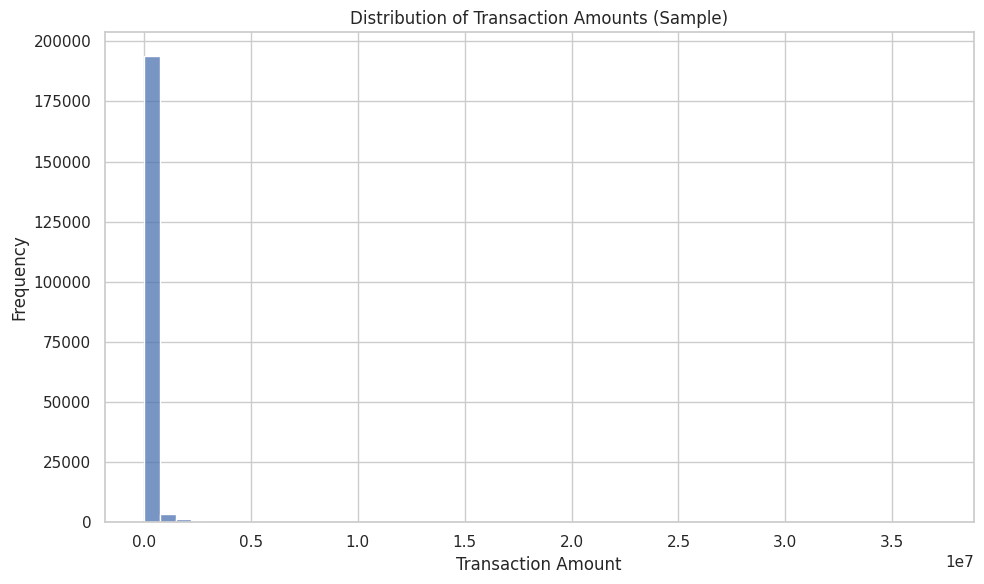

In [ ]:
plt.figure(figsize=(10, 6))

sns.histplot(
    data=df_eda,
    x="amount",
    bins=50
)

plt.title("Distribution of Transaction Amounts (Sample)")
plt.xlabel("Transaction Amount")
plt.ylabel("Frequency")
plt.tight_layout()
plt.show()

## Distribution of Fraudulent and Legitimate Transactions

The target variable `isFraud` identifies whether a transaction is fraudulent.

- `0` represents a legitimate transaction.
- `1` represents a fraudulent transaction.

This analysis compares the number of fraudulent and legitimate transactions. Understanding this distribution is important because an imbalanced dataset can make accuracy misleading when evaluating a fraud detection model.

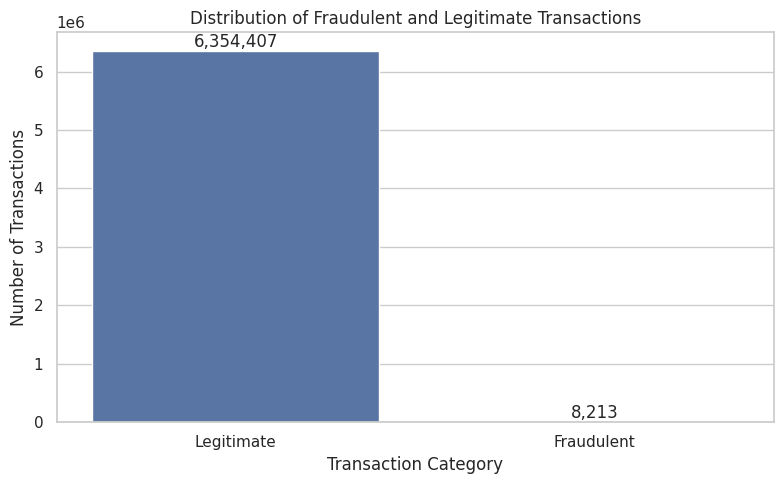

,Transaction Count,Percentage (%)
Legitimate,6354407,99.870918
Fraudulent,8213,0.129082


In [ ]:
# Count legitimate and fraudulent transactions
fraud_counts = df["isFraud"].value_counts().sort_index()

# Create labels
labels = ["Legitimate", "Fraudulent"]

# Plot the results
plt.figure(figsize=(8, 5))

sns.barplot(
    x=labels,
    y=fraud_counts.values
)

plt.title("Distribution of Fraudulent and Legitimate Transactions")
plt.xlabel("Transaction Category")
plt.ylabel("Number of Transactions")

# Display counts above the bars
for i, count in enumerate(fraud_counts.values):
    plt.text(i, count, f"{count:,}", ha="center", va="bottom")

plt.tight_layout()
plt.show()

# Display counts and percentages
fraud_summary = pd.DataFrame({
    "Transaction Count": fraud_counts.values,
    "Percentage (%)": fraud_counts.values / len(df) * 100
}, index=labels)

display(fraud_summary)

## Fraud Rate by Transaction Type

Different transaction types may have different fraud patterns.

In this section, we will calculate the number of fraudulent transactions within each transaction type and determine the fraud rate as a percentage of that type's total transactions.

This analysis will help identify transaction categories that deserve further investigation.

In [ ]:
# Group transactions by type and fraud status
fraud_by_type = pd.crosstab(
    df["type"],
    df["isFraud"]
)

# Ensure both target classes are present
fraud_by_type = fraud_by_type.reindex(
    columns=[0, 1],
    fill_value=0
)

# Rename columns
fraud_by_type.columns = [
    "Legitimate Transactions",
    "Fraudulent Transactions"
]

# Calculate total transactions for each type
fraud_by_type["Total Transactions"] = (
    fraud_by_type["Legitimate Transactions"]
    + fraud_by_type["Fraudulent Transactions"]
)

# Calculate fraud rate as a percentage
fraud_by_type["Fraud Rate (%)"] = (
    fraud_by_type["Fraudulent Transactions"]
    / fraud_by_type["Total Transactions"]
    * 100
)

display(fraud_by_type.sort_values(
    "Fraud Rate (%)",
    ascending=False
))

,Legitimate Transactions,Fraudulent Transactions,Total Transactions,Fraud Rate (%)
type,,,,
TRANSFER,528812,4097,532909,0.768799
CASH_OUT,2233384,4116,2237500,0.183955
CASH_IN,1399284,0,1399284,0.000000
DEBIT,41432,0,41432,0.000000
PAYMENT,2151495,0,2151495,0.000000


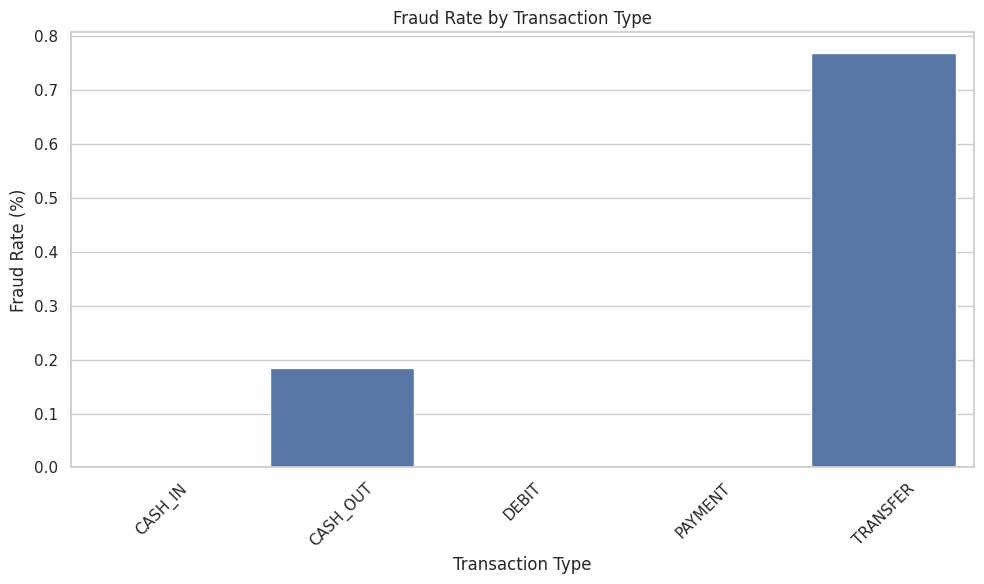

In [ ]:
plt.figure(figsize=(10, 6))

sns.barplot(
    data=fraud_by_type.reset_index(),
    x="type",
    y="Fraud Rate (%)"
)

plt.title("Fraud Rate by Transaction Type")
plt.xlabel("Transaction Type")
plt.ylabel("Fraud Rate (%)")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

### Observations: Fraud Rate by Transaction Type

The analysis reveals differences in fraud rates across transaction types.

- **TRANSFER** has the highest fraud rate at approximately 0.7688%.
- **CASH_OUT** has a fraud rate of approximately 0.1840%.
- **CASH_IN, DEBIT, and PAYMENT** have zero recorded fraudulent transactions in this dataset.
- Although CASH_OUT has more transactions overall, TRANSFER has the higher fraud rate.

**Conclusion:** TRANSFER and CASH_OUT deserve particular attention in further fraud analysis. However, a zero observed fraud rate in a category does not guarantee that such transactions can never be fraudulent.

## Transaction Amounts by Fraud Status

Transaction amount is an important feature to investigate in fraud detection.

In this section, we compare the transaction amounts of legitimate and fraudulent transactions using descriptive statistics and a box plot.

A box plot helps visualize the median, spread, and potential outliers in each group.

Since the dataset is highly imbalanced, we will use a sample for visualization and inspect the numerical summaries separately.

In [ ]:
# Separate transaction amounts by fraud status
legitimate_amounts = df.loc[df["isFraud"] == 0, "amount"]
fraudulent_amounts = df.loc[df["isFraud"] == 1, "amount"]

# Display descriptive statistics
print("Legitimate Transaction Amounts:")
display(legitimate_amounts.describe())

print("\nFraudulent Transaction Amounts:")
display(fraudulent_amounts.describe())

Legitimate Transaction Amounts:


,amount
count,6.354407e+06
mean,1.781970e+05
std,5.962370e+05
min,1.000000e-02
25%,1.336840e+04
50%,7.468472e+04
75%,2.083648e+05
max,9.244552e+07



Fraudulent Transaction Amounts:


,amount
count,8.213000e+03
mean,1.467967e+06
std,2.404253e+06
min,0.000000e+00
25%,1.270913e+05
50%,4.414234e+05
75%,1.517771e+06
max,1.000000e+07


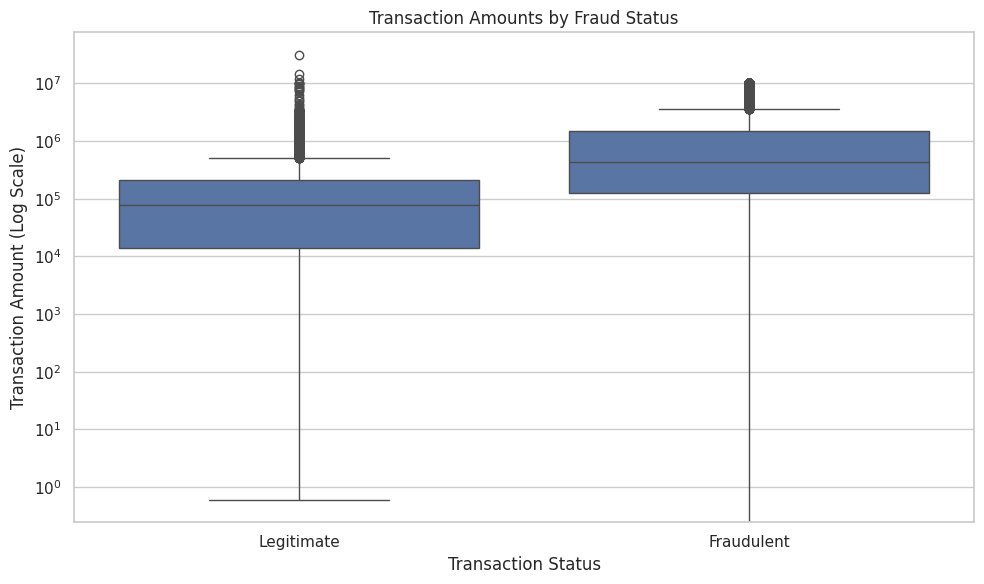

In [ ]:
# Take a reproducible sample of legitimate transactions
legitimate_sample = df.loc[
    df["isFraud"] == 0, ["amount"]
].sample(n=10000, random_state=42)

# Include all fraudulent transactions
fraudulent_sample = df.loc[
    df["isFraud"] == 1, ["amount"]
]

# Combine the samples
plot_data = pd.concat([
    legitimate_sample.assign(FraudStatus="Legitimate"),
    fraudulent_sample.assign(FraudStatus="Fraudulent")
], ignore_index=True)

# Plot transaction amounts on a logarithmic scale
plt.figure(figsize=(10, 6))

sns.boxplot(
    data=plot_data,
    x="FraudStatus",
    y="amount"
)

plt.yscale("log")
plt.title("Transaction Amounts by Fraud Status")
plt.xlabel("Transaction Status")
plt.ylabel("Transaction Amount (Log Scale)")
plt.tight_layout()
plt.show()

## Outlier Detection Using the IQR Method

Outliers are observations that differ substantially from the majority of the data.

In financial transaction datasets, unusually large transaction amounts may represent legitimate activity or potential fraud. Therefore, an outlier should not automatically be considered an error.

We will use the Interquartile Range (IQR) method to identify unusually low or high transaction amounts.

The IQR method uses the following calculations:

- **Q1:** 25th percentile
- **Q3:** 75th percentile
- **IQR:** Q3 − Q1
- **Lower bound:** Q1 − 1.5 × IQR
- **Upper bound:** Q3 + 1.5 × IQR

Values outside these bounds are flagged as potential outliers for further investigation.

In [ ]:
# Select the transaction amount column
amount = df["amount"]

# Calculate quartiles
Q1 = amount.quantile(0.25)
Q3 = amount.quantile(0.75)

# Calculate the interquartile range
IQR = Q3 - Q1

# Calculate the lower and upper bounds
lower_bound = Q1 - 1.5 * IQR
upper_bound = Q3 + 1.5 * IQR

# Count potential outliers
outlier_count = (
    (amount < lower_bound) |
    (amount > upper_bound)
).sum()

# Display results
print("Q1:", Q1)
print("Q3:", Q3)
print("IQR:", IQR)
print("Lower Bound:", lower_bound)
print("Upper Bound:", upper_bound)
print("Potential Outliers:", outlier_count)
print("Percentage of Potential Outliers:",
      round(outlier_count / len(df) * 100, 2), "%")

Q1: 13389.57
Q3: 208721.4775
IQR: 195331.9075
Lower Bound: -279608.29125
Upper Bound: 501719.33875
Potential Outliers: 338078
Percentage of Potential Outliers: 5.31 %


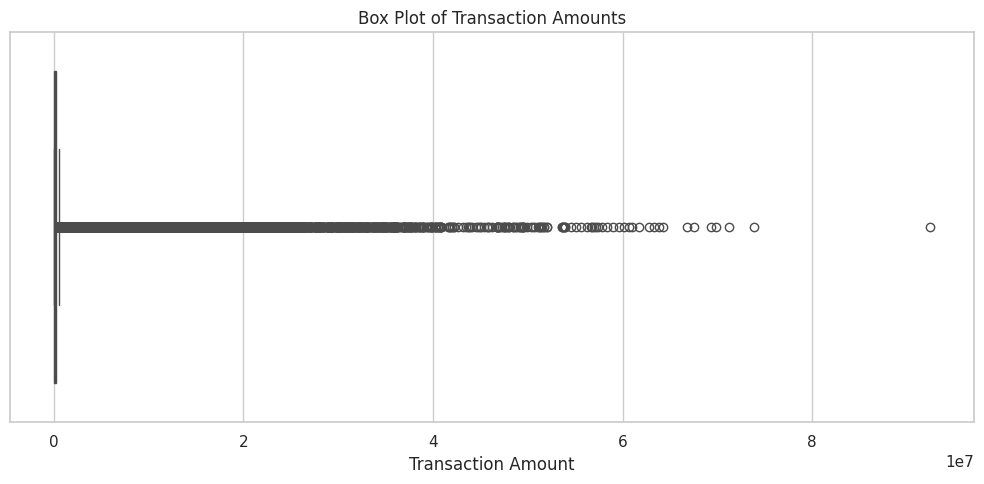

In [ ]:
plt.figure(figsize=(10, 5))

sns.boxplot(x=df["amount"])

plt.title("Box Plot of Transaction Amounts")
plt.xlabel("Transaction Amount")
plt.tight_layout()
plt.show()

### Results of IQR-Based Outlier Detection

The Interquartile Range (IQR) method was applied to the `amount` column to identify potential outliers.

The analysis produced the following results:

- **First quartile (Q1):** 13,389.57
- **Third quartile (Q3):** 208,721.48
- **Interquartile range (IQR):** 195,331.91
- **Lower bound:** -279,608.29
- **Upper bound:** 501,719.34
- **Potential outliers:** 338,078 transactions
- **Percentage of potential outliers:** 5.31%

Since transaction amounts cannot be negative in this dataset, no observations fall below the calculated lower bound. The potential outliers are therefore transactions with amounts exceeding approximately 501,719.34.

### Conclusion

The IQR method flags approximately 5.31% of transactions as potential outliers based on transaction amount alone. These transactions will be investigated further rather than automatically removed, because unusually large transactions may contain useful information for fraud detection.

## Transaction Amounts by Fraud Status

This analysis compares the transaction amounts associated with legitimate and fraudulent transactions.

The comparison can help identify differences in transaction values between the two classes. However, transaction amount alone cannot determine whether a transaction is fraudulent.

Median Transaction Amount by Fraud Status:
Legitimate: 74684.72
Fraudulent: 441423.44


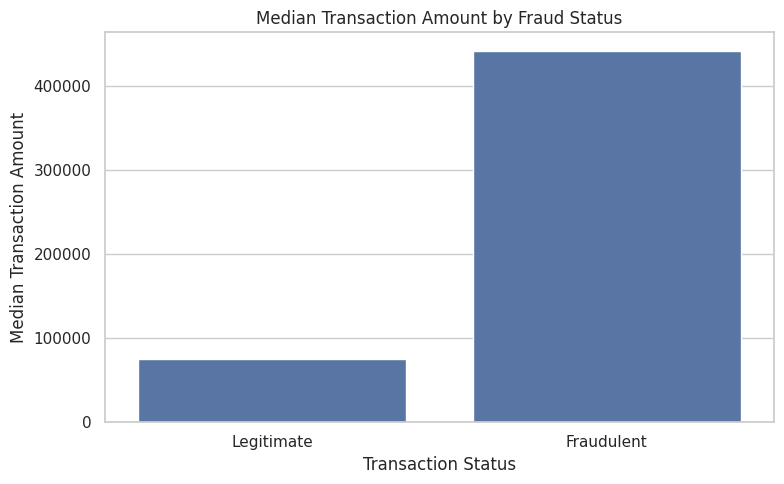

In [ ]:
# Calculate median transaction amount for each fraud class
median_amounts = df.groupby("isFraud")["amount"].median()

print("Median Transaction Amount by Fraud Status:")
print("Legitimate:", round(median_amounts.loc[0], 2))
print("Fraudulent:", round(median_amounts.loc[1], 2))

# Plot median transaction amounts
plt.figure(figsize=(8, 5))

sns.barplot(
    x=median_amounts.index.map({
        0: "Legitimate",
        1: "Fraudulent"
    }),
    y=median_amounts.values
)

plt.title("Median Transaction Amount by Fraud Status")
plt.xlabel("Transaction Status")
plt.ylabel("Median Transaction Amount")
plt.tight_layout()
plt.show()

### Observations: Transaction Amount by Fraud Status

The median transaction amount for legitimate transactions is 74,684.72, whereas the median for fraudulent transactions is 441,423.44.

The median fraudulent transaction amount is approximately 5.91 times higher than the median legitimate transaction amount.

This difference suggests that transaction amount may be a useful feature for fraud detection. However, the two groups may still contain overlapping transaction amounts, so this feature should not be used alone to classify transactions.

Further investigation and machine learning evaluation are required to determine how effectively transaction amount helps identify fraud.

# Exploratory Data Analysis — Summary

The EDA stage produced the following findings:

1. **Transaction types:** Transaction activity varies across the five transaction categories.
2. **Transaction amounts:** The amount distribution is strongly right-skewed, with a small number of very large transactions.
3. **Class imbalance:** Fraudulent transactions account for approximately 0.1291% of all transactions.
4. **Fraud by transaction type:** TRANSFER has the highest observed fraud rate at approximately 0.7688%, followed by CASH_OUT at approximately 0.1840%.
5. **Outliers:** The IQR method flagged 338,078 transactions (5.31%) as potential outliers based on transaction amount.
6. **Median amounts:** The median amount is 74,684.72 for legitimate transactions and 441,423.44 for fraudulent transactions.

### Conclusion

The dataset contains useful patterns for further fraud analysis, including class imbalance, differences in fraud rates across transaction types, and differences in transaction amounts.

These findings will guide the next stage of the project: data preprocessing and preparation for machine learning.

Potential outliers will be investigated rather than automatically deleted, and the class imbalance will be considered when training and evaluating the models.

# Stage 3: Data Preprocessing

## Objective

Data preprocessing prepares the transaction dataset for machine learning by ensuring that the features are represented appropriately and that the evaluation process avoids data leakage.

The following steps will be performed:

1. Inspect feature relevance and transaction identifiers.
2. Separate features and the target variable.
3. Split the data into training and testing sets.
4. Encode categorical variables.
5. Apply scaling and standardization where appropriate.
6. Investigate and justify outlier treatment.
7. Address class imbalance using training data only.

## Initial Feature Selection

The columns `nameOrig` and `nameDest` identify the originating and destination accounts. These identifiers will be excluded from the initial baseline because treating account IDs as ordinary numeric or categorical features could introduce excessive dimensionality or misleading patterns.

The remaining transaction attributes will be retained for initial modeling. The column `isFraud` is the target variable and will not be included among the input features.

The column `isFlaggedFraud` will be examined separately to determine whether its use is appropriate and whether it could create a misleading model.

In [ ]:
# Define the target variable
target = "isFraud"

# Exclude account identifiers from the initial baseline
excluded_columns = ["nameOrig", "nameDest", target]

# Create the feature matrix and target vector
X = df.drop(columns=excluded_columns)
y = df[target]

print("Feature matrix shape:", X.shape)
print("Target vector shape:", y.shape)

print("\nInput features:")
print(X.columns.tolist())

print("\nTarget distribution:")
print(y.value_counts())

Feature matrix shape: (6362620, 8)
Target vector shape: (6362620,)

Input features:
['step', 'type', 'amount', 'oldbalanceOrg', 'newbalanceOrig', 'oldbalanceDest', 'newbalanceDest', 'isFlaggedFraud']

Target distribution:
isFraud
0    6354407
1       8213
Name: count, dtype: int64


### Investigating the `isFlaggedFraud` Feature

The `isFlaggedFraud` column records transactions flagged by the original system. Before using it for prediction, we examine its relationship with `isFraud`.

This helps us identify whether the feature provides useful information or could introduce data leakage. We will decide whether to retain it after examining the results.

In [ ]:
# Check how many transactions were flagged
print("Distribution of isFlaggedFraud:")
print(df["isFlaggedFraud"].value_counts())

print("\nFlagged transactions by actual fraud status:")
print(pd.crosstab(
    df["isFlaggedFraud"],
    df["isFraud"],
    margins=True
))

print("\nNumber of transactions flagged by the original system:")
print(df["isFlaggedFraud"].sum())

print("\nFraudulent transactions flagged by the original system:")
print(df.loc[df["isFlaggedFraud"] == 1, "isFraud"].value_counts())

Distribution of isFlaggedFraud:
isFlaggedFraud
0    6362604
1         16
Name: count, dtype: int64

Flagged transactions by actual fraud status:
isFraud               0     1      All
isFlaggedFraud                        
0               6354407  8197  6362604
1                     0    16       16
All             6354407  8213  6362620

Number of transactions flagged by the original system:
16

Fraudulent transactions flagged by the original system:
isFraud
1    16
Name: count, dtype: int64


Feature Selection
The nameOrig and nameDest columns were excluded because they are account identifiers rather than direct transaction measurements.

The isFlaggedFraud column was also excluded from the initial model because only 16 transactions were flagged by the original system. Although all 16 were fraudulent, the feature captured only a very small proportion of all fraudulent transactions.

The target variable is isFraud. The initial model uses transaction type, transaction amount, time step, and account balance information as input features.

In [ ]:
# Define the target
target = "isFraud"

# Exclude identifiers and the original system's fraud flag
excluded_columns = [
    "nameOrig",
    "nameDest",
    "isFlaggedFraud",
    target
]

# Create features and target
X = df.drop(columns=excluded_columns)
y = df[target]

print("Feature matrix shape:", X.shape)
print("Target vector shape:", y.shape)

print("\nInput features:")
print(X.columns.tolist())

Feature matrix shape: (6362620, 7)
Target vector shape: (6362620,)

Input features:
['step', 'type', 'amount', 'oldbalanceOrg', 'newbalanceOrig', 'oldbalanceDest', 'newbalanceDest']


### Train-Test Split

The dataset is divided into 80% training data and 20% testing data. Stratified sampling is used to preserve the proportion of fraudulent and legitimate transactions in both sets.

The split is performed before fitting preprocessing transformations to prevent information from the test set from influencing the training process.

In [ ]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Training features:", X_train.shape)
print("Testing features:", X_test.shape)

print("\nFraud cases in training data:", int(y_train.sum()))
print("Fraud cases in testing data:", int(y_test.sum()))

print("\nFraud percentage in training data:",
      round(y_train.mean() * 100, 4), "%")

print("Fraud percentage in testing data:",
      round(y_test.mean() * 100, 4), "%")

Training features: (5090096, 7)
Testing features: (1272524, 7)

Fraud cases in training data: 6570
Fraud cases in testing data: 1643

Fraud percentage in training data: 0.1291 %
Fraud percentage in testing data: 0.1291 %


Encoding and Feature Scaling

The type column contains categorical transaction types, so it is converted into numerical indicator columns using One-Hot Encoding. Numerical features are standardized using StandardScaler, which transforms them to have approximately zero mean and unit variance.

The transformations are fitted only on the training data and then applied to the test data to avoid data leakage. The original dataset is retained for EDA and documentation.

In [ ]:
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler

# Identify categorical and numerical columns
categorical_features = ["type"]

numerical_features = [
    "step",
    "amount",
    "oldbalanceOrg",
    "newbalanceOrig",
    "oldbalanceDest",
    "newbalanceDest"
]

# Create the preprocessing pipeline
preprocessor = ColumnTransformer(
    transformers=[
        (
            "categorical",
            OneHotEncoder(handle_unknown="ignore"),
            categorical_features
        ),
        (
            "numerical",
            StandardScaler(),
            numerical_features
        )
    ]
)

# Fit on training data only
X_train_processed = preprocessor.fit_transform(X_train)

# Apply the same transformations to test data
X_test_processed = preprocessor.transform(X_test)

print("Processed training shape:", X_train_processed.shape)
print("Processed testing shape:", X_test_processed.shape)
print("Preprocessing completed successfully.")

Processed training shape: (5090096, 11)
Processed testing shape: (1272524, 11)
Preprocessing completed successfully.


In [ ]:
# Check the processed data
print("Training data shape:", X_train_processed.shape)
print("Testing data shape:", X_test_processed.shape)

print("\nTraining target shape:", y_train.shape)
print("Testing target shape:", y_test.shape)

print("\nMissing values in original dataset:", df.isnull().sum().sum())

Training data shape: (5090096, 11)
Testing data shape: (1272524, 11)

Training target shape: (5090096,)
Testing target shape: (1272524,)

Missing values in original dataset: 0


Outlier Detection and Treatment

The Interquartile Range (IQR) method was used to identify potential outliers in the transaction amount feature.

First quartile (Q1): 13,389.57

Third quartile (Q3): 208,721.48

IQR: 195,331.91

Upper bound: 501,719.34

Potential outliers: 338,078 (approximately 5.31%)

The potential outliers were retained in the main dataset because unusually large transactions may be relevant to fraud detection. Automatically removing these transactions could eliminate important fraud cases. Therefore, the decision to retain them is documented rather than treating every statistically unusual transaction as an error.

Preprocessing Summary

The dataset was checked for missing values and duplicate records. No missing values or exact duplicate records were found.

The nameOrig and nameDest identifier columns and the isFlaggedFraud feature were excluded from the initial model features. The categorical type feature was One-Hot Encoded, and numerical features were standardized using StandardScaler.

An 80:20 stratified train-test split was performed, preserving the fraud proportion in both sets. Potential outliers in transaction amounts were identified using the IQR method and retained in the main dataset because large transactions may be important for fraud analysis.